<Info | 8 non-empty values
 bads: []
 ch_names: Fp1, Fp2, F3, F4, C3, C4, P3, P4, O1, O2, F7, F8, T3, T4, T5, ...
 chs: 19 EEG
 custom_ref_applied: False
 dig: 22 items (3 Cardinal, 19 EEG)
 highpass: 0.0 Hz
 lowpass: 250.0 Hz
 meas_date: unspecified
 nchan: 19
 projs: []
 sfreq: 500.0 Hz
>
<Annotations | 0 segments>
Using matplotlib as 2D backend.


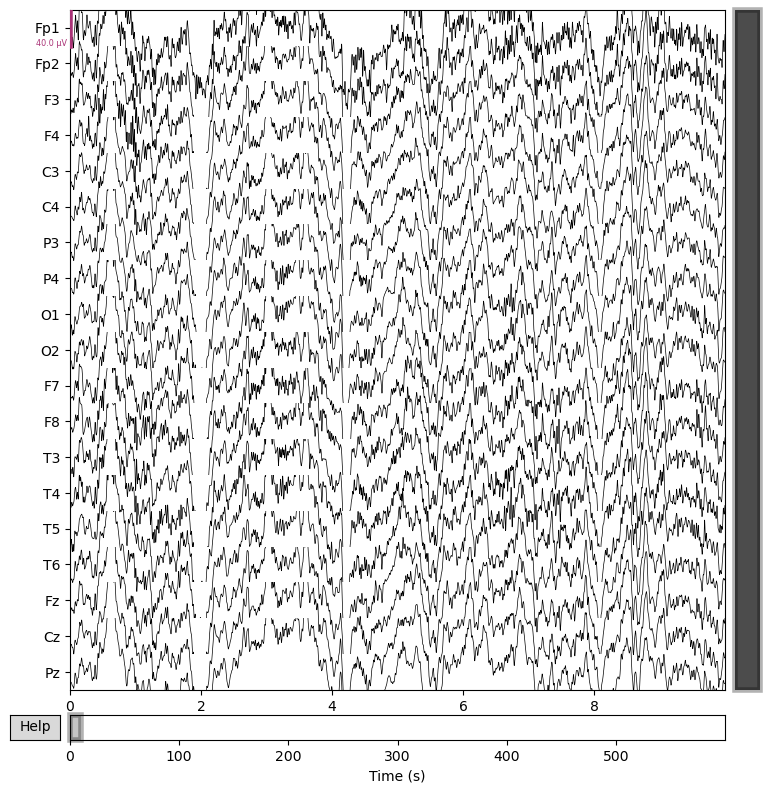

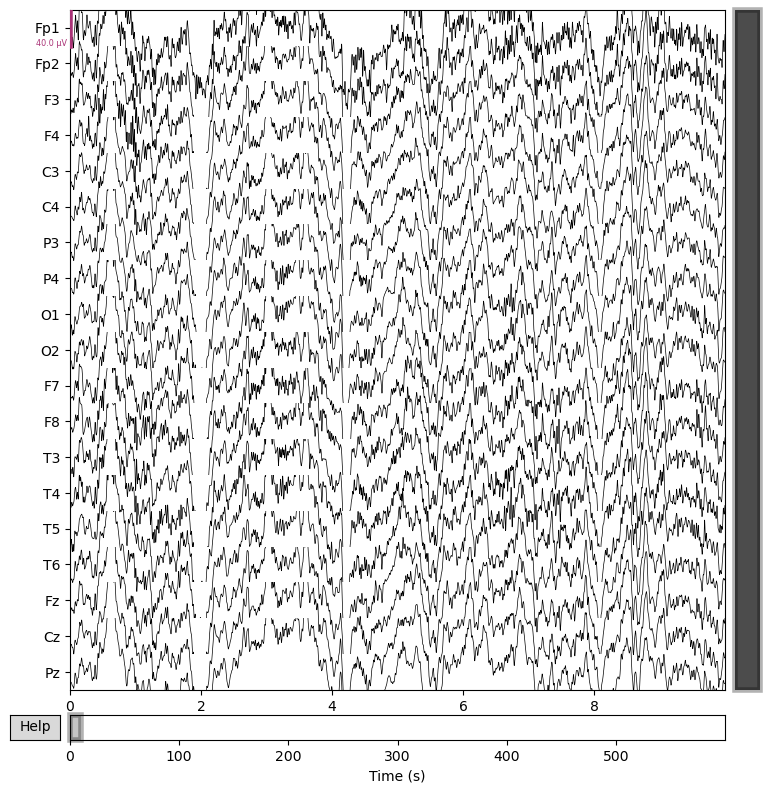

In [4]:
import mne

# Load the EEGLAB .set file
raw = mne.io.read_raw_eeglab("C:/Users/sanja/Desktop/March_Paper_data/dataset/sub-001_task-eyesclosed_eeg.set", preload=True)

# Print info about the dataset
print(raw.info)

# Check available annotations (events, markers, etc.)
print(raw.annotations)

# Plot raw EEG signals
raw.plot()


In [1]:
from scipy.io import loadmat

data = loadmat("C:/Users/sanja/Desktop/March_Paper_data/dataset/sub-001_task-eyesclosed_eeg.set")
print(data.keys())


dict_keys(['__header__', '__version__', '__globals__', 'setname', 'filename', 'filepath', 'subject', 'group', 'condition', 'session', 'comments', 'nbchan', 'trials', 'pnts', 'srate', 'xmin', 'xmax', 'times', 'data', 'icaact', 'icawinv', 'icasphere', 'icaweights', 'icachansind', 'chanlocs', 'urchanlocs', 'chaninfo', 'ref', 'event', 'urevent', 'eventdescription', 'epoch', 'epochdescription', 'reject', 'stats', 'specdata', 'specicaact', 'splinefile', 'icasplinefile', 'dipfit', 'history', 'saved', 'etc', 'run', 'datfile', 'BIDS', 'task'])


In [4]:
import os
import mne
import numpy as np
import pandas as pd

# Folder containing your .set files
data_folder = "C:/Users/sanja/Desktop/March_Paper_data/dataset"

# Define frequency bands
freq_bands = {
    "delta": (1, 4),
    "theta": (4, 8),
    "alpha": (8, 12),
    "beta": (12, 30),
    "gamma": (30, 40)
}

# Function to extract bandpower from epochs
def compute_bandpower(epochs, bands):
    try:
        # Newer MNE (>=1.5) uses mne.time_frequency.psd_array_welch
        psd, freqs = mne.time_frequency.psd_array_welch(
            epochs.get_data(), sfreq=epochs.info["sfreq"], fmin=1, fmax=40, n_fft=256, average="mean"
        )
    except AttributeError:
        # Older MNE (<1.5) uses epochs.compute_psd()
        psd = epochs.compute_psd(fmin=1, fmax=40, n_fft=256)
        freqs = psd.freqs
        psd = psd.get_data()

    bandpower = {}
    for band, (fmin, fmax) in bands.items():
        idx_band = np.logical_and(freqs >= fmin, freqs <= fmax)
        bp = psd[:, :, idx_band].mean(axis=-1)  # mean across freqs
        bandpower[band] = bp.mean(axis=1)       # mean across channels
    return bandpower

# Store results
all_features = []

# Loop through dataset
for file in os.listdir(data_folder):
    if file.endswith(".set"):
        filepath = os.path.join(data_folder, file)
        print(f"Processing {file}...")

        # Load raw EEG
        raw = mne.io.read_raw_eeglab(filepath, preload=True)

        # Preprocessing
        raw.filter(1., 40.)                        # bandpass filter
        raw.set_eeg_reference('average')           # average reference

        # Epoching (2s windows with 50% overlap)
        epochs = mne.make_fixed_length_epochs(raw, duration=2.0, overlap=1.0, preload=True)

        # Feature extraction
        bandpower = compute_bandpower(epochs, freq_bands)

        # Save features
        feature_row = {"filename": file}
        for band in freq_bands.keys():
            feature_row[f"{band}_power"] = bandpower[band].mean()  # mean across epochs

        all_features.append(feature_row)

# Convert to DataFrame
df = pd.DataFrame(all_features)

# Save to CSV
df.to_csv("EEG_features.csv", index=False)
print("✅ Features saved to EEG_features.csv")


Processing sub-001_task-eyesclosed_eeg.set...
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 1651 samples (3.302 s)

EEG channel type selected for re-referencing
Applying average reference.
Applying a custom ('EEG',) reference.
Not setting metadata
598 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 598 events and 1000 original time points ...
0 bad epochs dropped
Effective window size : 0.512 (s)
Processing sub-002_task-eyesclosed_eeg.s

C:\Users\sanja\AppData\Local\Temp\ipykernel_3100\3020484926.py:48: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(filepath, preload=True)


0 bad epochs dropped
Effective window size : 0.512 (s)
Processing sub-004_task-eyesclosed_eeg.set...
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 1651 samples (3.302 s)

EEG channel type selected for re-referencing
Applying average reference.
Applying a custom ('EEG',) reference.


C:\Users\sanja\AppData\Local\Temp\ipykernel_3100\3020484926.py:48: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(filepath, preload=True)


Not setting metadata
705 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 705 events and 1000 original time points ...
0 bad epochs dropped
Effective window size : 0.512 (s)
Processing sub-005_task-eyesclosed_eeg.set...
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 1651 samples (3.302 s)

EEG channel type selected for re-referencing
Applying average reference.
Applying a custom ('EEG',) reference.
Not setting metadata
803 matching events

...

EEG channel type selected for re-referencing
Applying average reference.
Applying a custom ('EEG',) reference.
Not setting metadata
897 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 897 events and 1000 original time points ...
0 bad epochs dropped
Effective window size : 0.512 (s)
Processing sub-027_task-eyesclosed_eeg.set...
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 1651 samples (3.302 s)

EEG channel type selected for re-referen

C:\Users\sanja\AppData\Local\Temp\ipykernel_3100\3020484926.py:48: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(filepath, preload=True)


Not setting metadata
825 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 825 events and 1000 original time points ...
0 bad epochs dropped
Effective window size : 0.512 (s)
Processing sub-028_task-eyesclosed_eeg.set...
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 1651 samples (3.302 s)

EEG channel type selected for re-referencing
Applying average reference.
Applying a custom ('EEG',) reference.


C:\Users\sanja\AppData\Local\Temp\ipykernel_3100\3020484926.py:48: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(filepath, preload=True)


Not setting metadata
817 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 817 events and 1000 original time points ...
0 bad epochs dropped
Effective window size : 0.512 (s)
Processing sub-029_task-eyesclosed_eeg.set...
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 1651 samples (3.302 s)

EEG channel type selected for re-referencing
Applying average reference.
Applying a custom ('EEG',) reference.
Not setting metadata
739 matching events